# Medical Device Adverse Event Analysis — openFDA API, Python, SQL
**Business question:** Which medical device types generate the most adverse event reports, how is report volume trending, and how clean is the public data?

**Pipeline:** REST API → pandas cleaning → data-quality checks → SQLite → SQL analysis → charts → findings

Data: FDA MAUDE adverse event reports via the public openFDA API (real, public data). Reports are not proof a device caused harm.

In [1]:
import requests, time, sqlite3, json
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 60)

## 1. Pull data from the openFDA REST API

In [2]:
# Free key: https://open.fda.gov/apis/authentication/  (paste yours between the quotes, and delete it before uploading)
API_KEY = ""

BASE = "https://api.fda.gov/device/event.json"
MONTHS = [("2025%02d01" % m, "2025%02d28" % m) for m in range(1, 11)]   # Jan-Oct 2025
PAGE = 1000                                                             # 1,000 reports per month = 10,000

def get(params):
    if API_KEY:
        params["api_key"] = API_KEY
    for attempt in range(3):                       # retry on errors / rate limits
        r = requests.get(BASE, params=params, timeout=30)
        if r.status_code == 200:
            return r.json()
        time.sleep(2 * (attempt + 1))
    r.raise_for_status()

# 1) sample 1,000 reports from each month so the data covers the whole year
records, log = [], []
for start, end in MONTHS:
    data = get({"search": f"date_received:[{start} TO {end}]", "limit": PAGE})
    records.extend(data["results"])
    log.append((start, len(data["results"])))
    time.sleep(1)

# 2) real daily report totals for all of 2025 (used for the monthly trend)
counts = get({"search": "date_received:[20250101 TO 20251231]", "count": "date_received"})["results"]
daily = pd.DataFrame(counts).rename(columns={"time": "day", "count": "reports"})

print(f"API calls: {len(log) + 1} | sampled reports: {len(records):,} | days with totals: {len(daily)}")


API calls: 11 | sampled reports: 10,000 | days with totals: 348


## 2. Flatten the nested JSON into a table

In [15]:
def first(lst):
    return lst[0] if isinstance(lst, list) and lst else {}

rows = []
for rec in records:
    dev = first(rec.get("device"))
    ofda = dev.get("openfda", {}) or {}
    rows.append({

               "report_id":      rec.get("mdr_report_key"),
        "date_received":  rec.get("date_received"),
        "date_of_event":  rec.get("date_of_event"),
        "event_type":     rec.get("event_type"),
        "report_source":  rec.get("report_source_code"),
        "generic_name":   dev.get("generic_name"),
        "brand_name":     dev.get("brand_name"),
        "manufacturer":   dev.get("manufacturer_d_name"),
        "product_code":   dev.get("device_report_product_code"),
        "device_class":   ofda.get("device_class"),
        "specialty":      ofda.get("medical_specialty_description"),
    })
raw = pd.DataFrame(rows)
print(raw.shape); raw.head()

(10000, 11)


,report_id,date_received,date_of_event,event_type,report_source,generic_name,brand_name,manufacturer,product_code,device_class,specialty
0,21050632,20250101,20241209,Malfunction,Manufacturer report,"SYSTEM, BALLOON, INTRA-AORTIC AND CONTROL","CARDIOSAVE HYBRID, TYPE G PLUG",DATASCOPE CORP.,DSP,2,Cardiovascular
1,21050633,20250101,20241211,Malfunction,Manufacturer report,"SYSTEM, BALLOON, INTRA-AORTIC AND CONTROL","CARDIOSAVE HYBRID, TYPE B PLUG",DATASCOPE CORP.,DSP,2,Cardiovascular
2,21050634,20250101,20241201,Injury,Manufacturer report,"AUTOMATED INSULIN DOSING DEVICE SYSTEM, SINGLE HORMONAL ...",MINIMED 780G US SYSTEM BLE CONNECT 3.0 MG/DL,MEDTRONIC PUERTO RICO OPERATIONS CO.,OZP,3,Unknown
3,21050635,20250101,20231009,Injury,Manufacturer report,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",DREAMSTATION AUTO CPAP,"RESPIRONICS, INC.",BZD,2,Anesthesiology
4,21050636,20250101,20231009,Injury,Manufacturer report,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",DREAMSTATION AUTO CPAP,"RESPIRONICS, INC.",BZD,2,Anesthesiology


## 3. Data-quality audit (before cleaning)

In [4]:
def audit(df, label):
    out = pd.DataFrame({
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique":    df.nunique(),
    })
    print(f"--- {label}: {len(df):,} rows | duplicate report IDs: {df['report_id'].duplicated().sum():,}")
    return out
audit(raw, "RAW")

--- RAW: 10,000 rows | duplicate report IDs: 0


,missing_%,unique
report_id,0.0,10000
date_received,0.0,11
date_of_event,9.4,865
event_type,0.0,3
report_source,0.0,4
generic_name,0.0,658
brand_name,0.0,1642
manufacturer,0.0,324
product_code,0.0,325
device_class,0.0,5


## 4. Clean and standardize

In [5]:
df = raw.copy()
n0 = len(df)

# remove duplicate reports
df = df.drop_duplicates(subset="report_id")
n_dupes = n0 - len(df)

# parse dates (YYYYMMDD strings) — bad values become NaT
for c in ["date_received", "date_of_event"]:
    df[c] = pd.to_datetime(df[c], format="%Y%m%d", errors="coerce")

# standardize text fields
for c in ["generic_name", "brand_name", "manufacturer", "event_type", "specialty"]:
    df[c] = df[c].astype("string").str.strip().str.upper()

# normalize event types
df["event_type"] = df["event_type"].replace({"NO ANSWER PROVIDED": pd.NA, "*": pd.NA}).fillna("UNKNOWN")

# reporting lag (days between event and FDA receipt); flag impossible values
df["lag_days"] = (df["date_received"] - df["date_of_event"]).dt.days
bad_lag = ((df["lag_days"] < 0) | (df["lag_days"] > 3650)).sum()
df.loc[(df["lag_days"] < 0) | (df["lag_days"] > 3650), "lag_days"] = pd.NA

print(f"Removed duplicates: {n_dupes:,} | invalid lags flagged: {bad_lag:,} | clean rows: {len(df):,}")
audit(df, "CLEAN")

Removed duplicates: 0 | invalid lags flagged: 22 | clean rows: 10,000
--- CLEAN: 10,000 rows | duplicate report IDs: 0


,missing_%,unique
report_id,0.0,10000
date_received,0.0,11
date_of_event,9.4,865
event_type,0.0,3
report_source,0.0,4
generic_name,0.0,641
brand_name,0.0,1637
manufacturer,0.0,323
product_code,0.0,325
device_class,0.0,5


## 5. Load into SQLite

In [6]:
con = sqlite3.connect("device_events.db")
out = df.copy()
for c in ["date_received", "date_of_event"]:
    out[c] = out[c].dt.strftime("%Y-%m-%d")
out.to_sql("events", con, if_exists="replace", index=False)
daily.to_sql("daily_counts", con, if_exists="replace", index=False)   # real totals for the trend
sql = lambda q: pd.read_sql(q, con)
sql("SELECT COUNT(*) AS rows_loaded FROM events")


,rows_loaded
0,10000


## 6. SQL analysis

In [7]:
# Q1: event type breakdown
q1 = sql("""
SELECT event_type, COUNT(*) AS reports,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM events), 1) AS pct
FROM events GROUP BY event_type ORDER BY reports DESC""")
q1

,event_type,reports,pct
0,MALFUNCTION,5843,58.4
1,INJURY,4117,41.2
2,DEATH,40,0.4


In [8]:
# Q2: top 10 device types by report volume, with injury/death share
q2 = sql("""
SELECT generic_name, COUNT(*) AS reports,
       SUM(event_type IN ('INJURY','DEATH')) AS serious,
       ROUND(100.0 * SUM(event_type IN ('INJURY','DEATH')) / COUNT(*), 1) AS serious_pct
FROM events WHERE generic_name IS NOT NULL
GROUP BY generic_name ORDER BY reports DESC LIMIT 10""")
q2

,generic_name,reports,serious,serious_pct
0,ENDOSSEOUS DENTAL IMPLANT,1536,1534,99.9
1,"AUTOMATED INSULIN DOSING DEVICE SYSTEM, SINGLE HORMONAL ...",1206,145,12.0
2,CONTINUOUS GLUCOSE MONITOR,839,0,0.0
3,"IMPLANT, ENDOSSEOUS, ROOT-FORM",838,838,100.0
4,"VENTILATOR, NON-CONTINUOUS (RESPIRATOR)",386,135,35.0
5,DENTAL IMPLANT,325,325,100.0
6,ALTERNATE CONTROLLER ENABLED INSULIN INFUSION PUMP,302,38,12.6
7,"PUMP, INFUSION",189,1,0.5
8,FLASH GLUCOSE MONITORING SYSTEM,174,4,2.3
9,"SENSOR, GLUCOSE, INVASIVE , NON-ADJUNCTIVE",169,0,0.0


In [9]:
# Q3: real monthly report totals with month-over-month % change (CTE + LAG window function)
q3 = sql("""
WITH m AS (
  SELECT substr(day, 1, 6) AS month, SUM(reports) AS reports
  FROM daily_counts GROUP BY month)
SELECT month, reports,
       ROUND(100.0 * (reports - LAG(reports) OVER (ORDER BY month))
             / LAG(reports) OVER (ORDER BY month), 1) AS mom_pct
FROM m ORDER BY month""")
q3


,month,reports,mom_pct
0,202501,238815,NaN
1,202502,210014,-12.1
2,202503,236422,12.6
3,202504,204562,-13.5
4,202505,180281,-11.9
5,202506,247453,37.3
6,202507,315612,27.5
7,202508,245788,-22.1
8,202509,258044,5.0
9,202510,256791,-0.5


In [10]:
# Q4: top manufacturers + median-ish reporting lag
q4 = sql("""
SELECT manufacturer, COUNT(*) AS reports, ROUND(AVG(lag_days), 0) AS avg_lag_days
FROM events WHERE manufacturer IS NOT NULL
GROUP BY manufacturer ORDER BY reports DESC LIMIT 10""")
q4

,manufacturer,reports,avg_lag_days
0,NOBEL BIOCARE AB GÖTEBORG,1523,185.0
1,MEDTRONIC PUERTO RICO OPERATIONS CO.,1328,36.0
2,"DEXCOM, INC.",839,32.0
3,MIS IMPLANTS TECHNOLOGIES LTD.,467,33.0
4,MEDTRONIC MINIMED,455,35.0
5,"RESPIRONICS, INC.",403,726.0
6,DENTSPLY IMPLANTS MANUFACTURING GMBH,353,122.0
7,INSULET CORPORATION,270,28.0
8,ADIN DENTAL IMPLANT SYSTEMS LTD,254,717.0
9,UNOMEDICAL DEVICES S.A. DE C.V.,248,49.0


In [11]:
# Q5: reports by medical specialty (where openFDA classified it)
q5 = sql("""
SELECT COALESCE(specialty, 'UNCLASSIFIED') AS specialty, COUNT(*) AS reports
FROM events GROUP BY 1 ORDER BY reports DESC LIMIT 10""")
q5

,specialty,reports
0,DENTAL,3000
1,UNKNOWN,2151
2,CLINICAL CHEMISTRY,1813
3,GENERAL HOSPITAL,809
4,ANESTHESIOLOGY,659
5,"GASTROENTEROLOGY, UROLOGY",409
6,CARDIOVASCULAR,408
7,"GENERAL, PLASTIC SURGERY",258
8,ORTHOPEDIC,141
9,RADIOLOGY,92


## 7. Charts

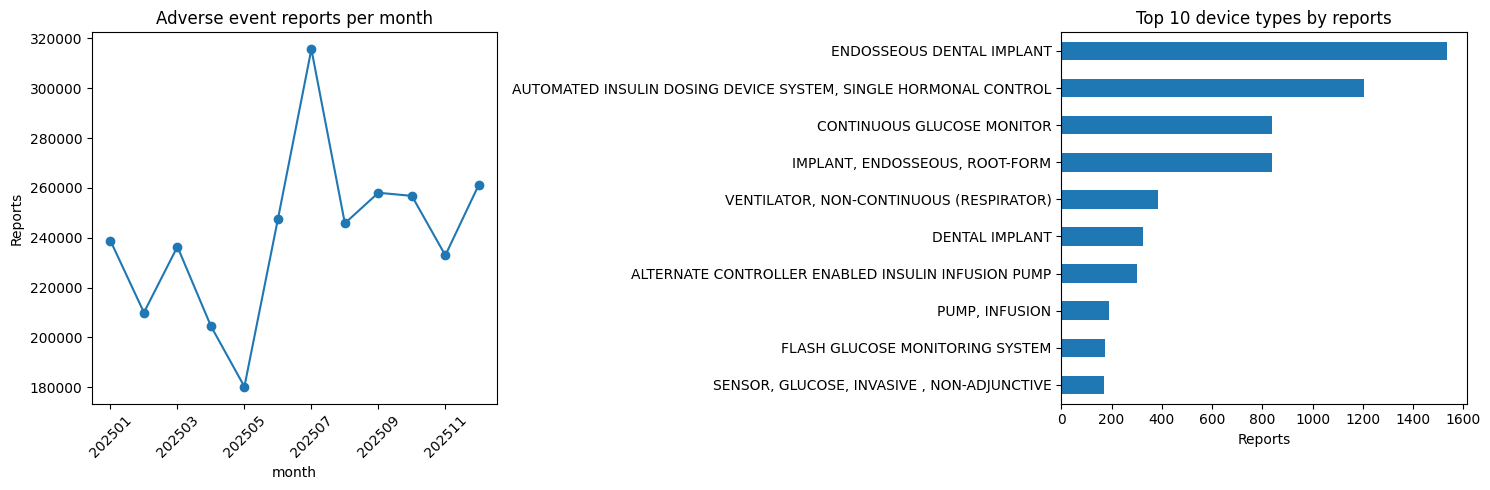

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
q3.plot(x="month", y="reports", marker="o", ax=ax[0], legend=False)
ax[0].set_title("Adverse event reports per month"); ax[0].set_ylabel("Reports"); ax[0].tick_params(axis="x", rotation=45)
q2.sort_values("reports").plot.barh(x="generic_name", y="reports", ax=ax[1], legend=False)
ax[1].set_title("Top 10 device types by reports"); ax[1].set_xlabel("Reports"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig("dashboard.png", dpi=150); plt.show()

## 8. Validation checks (automated)

In [13]:
checks = {
    "no duplicate report IDs":        df["report_id"].duplicated().sum() == 0,
    "all rows loaded to SQL":         sql("SELECT COUNT(*) n FROM events")["n"][0] == len(df),
    "event-type % sums to ~100":      abs(q1["pct"].sum() - 100) < 0.5,
    "no negative reporting lags":     (df["lag_days"].dropna() >= 0).all(),
    "all received dates in 2025":     df["date_received"].dropna().dt.year.eq(2025).all(),
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
assert all(checks.values()), "A validation check failed"

PASS no duplicate report IDs
PASS all rows loaded to SQL
PASS event-type % sums to ~100
PASS no negative reporting lags
PASS all received dates in 2025


## 9. Results summary — copy these numbers to your resume

In [14]:
top = q2.iloc[0]
print(f"Reports pulled: {len(records):,} via {len(log)} API calls")
print(f"Duplicates removed: {n_dupes:,} | invalid lags flagged: {bad_lag:,}")
print(f"Clean rows in SQL: {len(df):,}")
print(f"Top device type: {top['generic_name']} ({top['reports']:,} reports, {top['serious_pct']}% injury/death)")
print(f"Malfunction share: {q1.set_index('event_type')['pct'].get('MALFUNCTION', 0)}%")
print(f"Validation checks passed: {sum(checks.values())}/{len(checks)}")

Reports pulled: 10,000 via 10 API calls
Duplicates removed: 0 | invalid lags flagged: 22
Clean rows in SQL: 10,000
Top device type: ENDOSSEOUS DENTAL IMPLANT (1,536 reports, 99.9% injury/death)
Malfunction share: 58.4%
Validation checks passed: 5/5


## 10. Findings (PAFR) — fill in after running
- **Problem:**
- **Approach:** Pulled N reports from the openFDA REST API, cleaned/deduplicated in pandas, loaded to SQLite, analyzed with SQL (aggregations, CTE, LAG window function), and ran 5 automated validation checks.
- **Findings:**
- **Recommendation:**